# 👥 Customer Behavior & RFM Segmentation Analysis
### Data Analytics Portfolio Project | Python, Pandas, Matplotlib, Seaborn & SQL
---
**Author:** Data Analyst Portfolio  
**Date:** 2026  
**Dataset:** Customer Profiles & Multi-Channel Transactions (4,200 orders across 1,200 customers)  
**Database:** Embedded SQLite (`customer_analytics.db`)  

## 1. Executive Summary & Business Problem
Understanding customer lifetime value (LTV), buying cadences, and churn risk is essential for modern customer-centric businesses. Without rigorous behavioral segmentation, marketing teams risk treating high-value VIPs identically to one-off discount hunters.

### Business Goals:
1. **Cleanse & Prepare Data:** Audit customer demographic tables and transaction logs, standardizing casing, nulls, and duplicate entries.
2. **Relational Database Design:** Load normalized tables into an indexed SQLite relational database for production SQL querying.
3. **SQL Business Queries:** Implement CTEs, Window Functions (`NTILE`, `RANK`, `SUM() OVER`), and aggregations to evaluate customer purchasing power.
4. **RFM Segmentation:** Group customers into **Champions**, **Loyal Customers**, **Potential Loyalists**, **At Risk**, **Hibernating**, and **Lost** cohorts.
5. **Churn & Retention Diagnostics:** Pinpoint high-value customers slipping into churn to formulate targeted win-back campaigns.

## 2. Environment Setup & SQL Database Connection

In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

db_path = os.path.join('..', 'data', 'customer_analytics.db')
conn = sqlite3.connect(db_path)
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn)['name'].tolist()
print('Libraries loaded successfully.')
print(f'Connected to SQLite Database: {os.path.basename(db_path)}')
print(f'Available Database Tables: {tables}')

Libraries loaded successfully.
Connected to SQLite Database: customer_analytics.db
Available Database Tables: ['customers', 'transactions', 'customer_rfm_summary']


## 3. Data Cleaning & Preparation Summary
- Audited 1,220 raw customer records -> Removed 20 duplicates -> 1,200 clean profiles.
- Audited 4,235 raw transactions -> Removed 35 duplicates -> 4,200 clean transactions.
- Standardized inconsistent `Gender` values ('m', 'f', 'female', 'Male') into consistent categories.
- Imputed missing `Age` with median (36 years) and missing `Income_Bracket` with mode (`Medium`).
- Imputed missing transaction sales `Channel` with mode (`Mobile App`).

In [2]:
df_clean = pd.read_csv(os.path.join('..', 'data', 'cleaned_customer_data.csv'))
print(f'Clean Master Customer Dataset Shape: {df_clean.shape}')
print(f'Total Revenue Across Transactions: ${df_clean["Total_Spend"].sum():,.2f}')
print(f'Overall Average Order Value: ${df_clean[df_clean["Total_Orders"] > 0]["Average_Order_Value"].mean():,.2f}')

Clean Master Customer Dataset Shape: (1200, 17)
Total Revenue Across Transactions: $380,071.48
Overall Average Order Value: $90.49


## 4. SQL Analytics: Top 10 High-Value VIP Customers
Querying customer transaction totals using `INNER JOIN`, `GROUP BY`, and `ORDER BY`.

In [3]:
query_vip = """
SELECT 
    c.Customer_ID,
    c.City,
    c.Membership_Level,
    c.Income_Bracket,
    COUNT(t.Transaction_ID) AS Total_Orders,
    SUM(t.Items_Count) AS Total_Units,
    ROUND(SUM(t.Purchase_Amount), 2) AS Lifetime_Spend,
    ROUND(AVG(t.Purchase_Amount), 2) AS AOV
FROM customers c
INNER JOIN transactions t ON c.Customer_ID = t.Customer_ID
GROUP BY c.Customer_ID, c.City, c.Membership_Level, c.Income_Bracket
ORDER BY Lifetime_Spend DESC
LIMIT 5;
"""
pd.read_sql_query(query_vip, conn)

Customer_ID,City,Membership_Level,Income_Bracket,Total_Orders,Total_Units,Lifetime_Spend,AOV
CUST-1396,Seattle,Silver,Very High,9,19,"$1,349.68",$149.96
CUST-1274,Austin,Silver,Very High,10,19,"$1,302.15",$130.22
CUST-2192,New York,Bronze,Medium,7,15,"$1,289.72",$184.25
CUST-1507,Denver,Gold,Medium,7,15,"$1,274.43",$182.06
CUST-1443,Seattle,Silver,Medium,3,10,"$1,264.48",$421.49


## 5. SQL Analytics: Channel Performance Breakdown
Analyzing transaction volume and revenue generation across Mobile App, Web, and In-Store.

In [4]:
query_channel = """
SELECT 
    t.Channel,
    COUNT(t.Transaction_ID) AS Transactions,
    ROUND(COUNT(t.Transaction_ID) * 100.0 / (SELECT COUNT(*) FROM transactions), 2) AS Txn_Pct,
    ROUND(SUM(t.Purchase_Amount), 2) AS Total_Revenue,
    ROUND(SUM(t.Purchase_Amount) * 100.0 / (SELECT SUM(Purchase_Amount) FROM transactions), 2) AS Revenue_Pct,
    ROUND(AVG(t.Purchase_Amount), 2) AS Avg_Order_Size
FROM transactions t
GROUP BY t.Channel
ORDER BY Total_Revenue DESC;
"""
pd.read_sql_query(query_channel, conn)

Channel,Transactions,Txn_Pct,Total_Revenue,Revenue_Pct,Avg_Order_Size
Mobile App,"2,378",56.62%,"$215,132.72",56.60%,$90.47
Web,"1,441",34.31%,"$128,539.46",33.82%,$89.20
In-Store,381,9.07%,"$36,399.30",9.58%,$95.54


## 6. RFM Behavioral Segmentation & Quartile Scoring
Using Recency (R), Frequency (F), and Monetary (M) scores to categorize customers.

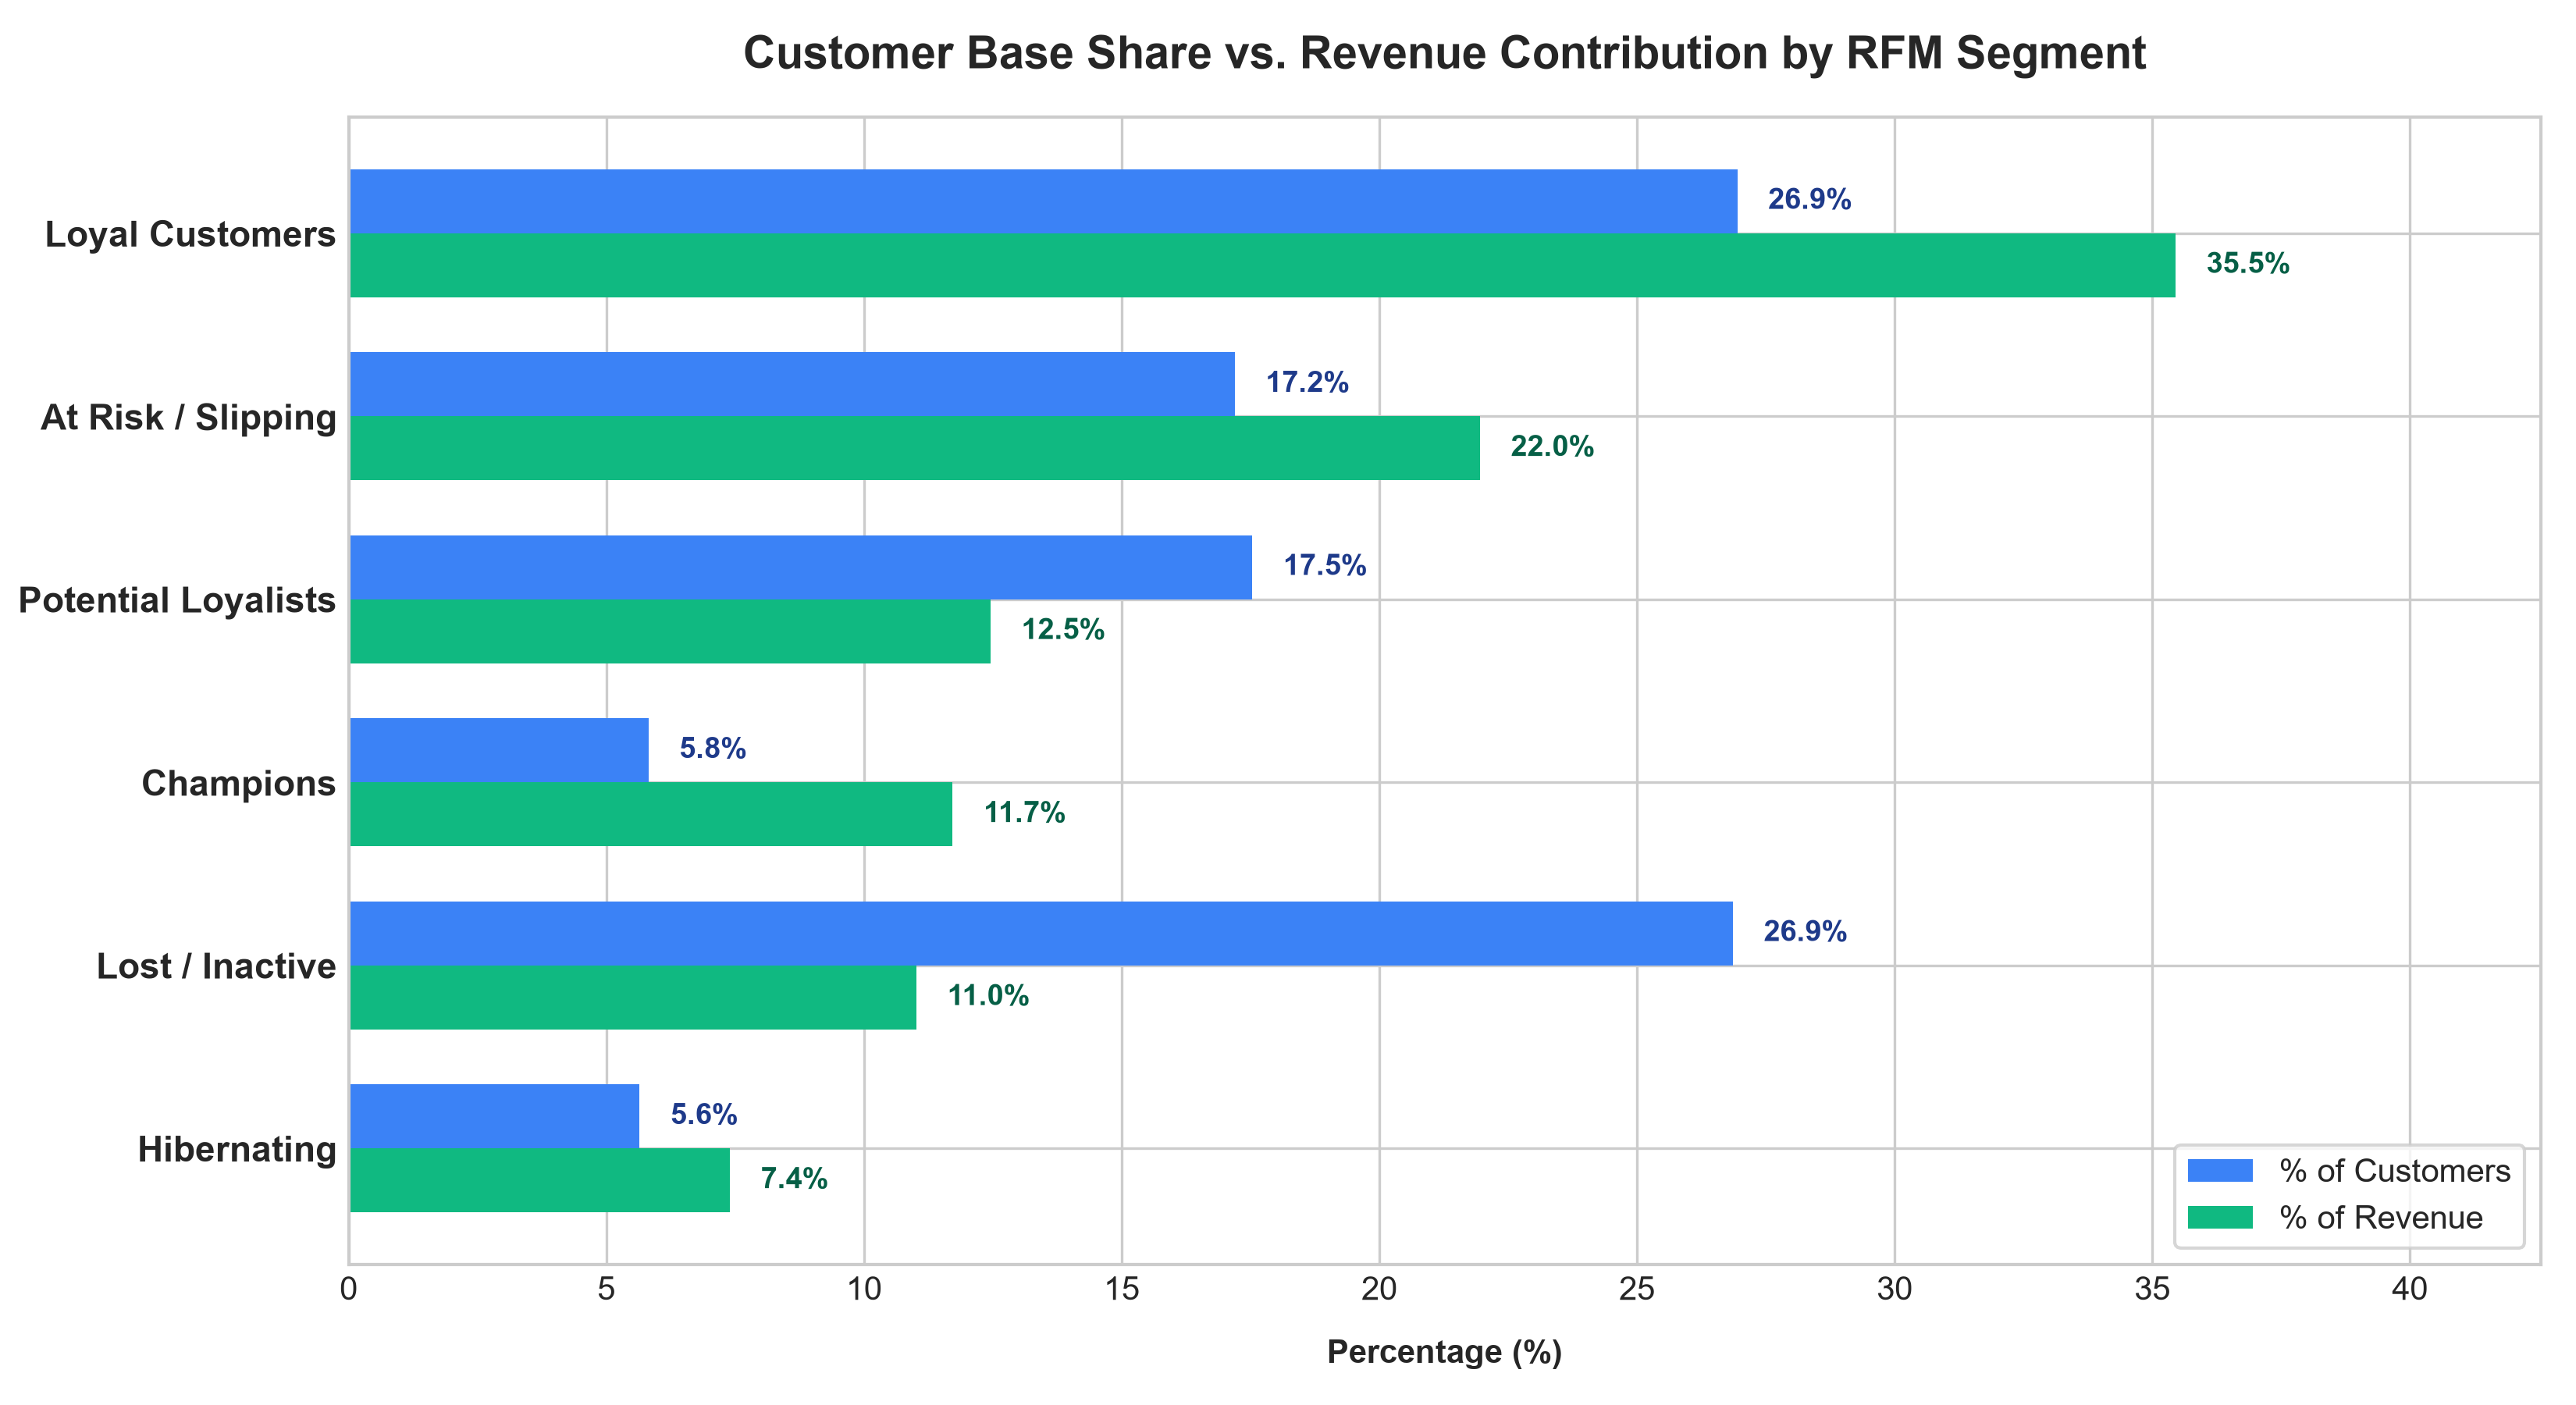

In [5]:
# Visualized from src/rfm_segmentation.py
query_rfm = """
WITH Customer_RFM AS (
    SELECT 
        Customer_ID,
        CAST(JULIANDAY('2025-11-01') - JULIANDAY(MAX(Transaction_Date)) AS INTEGER) AS Recency_Days,
        COUNT(Transaction_ID) AS Frequency,
        SUM(Purchase_Amount) AS Monetary
    FROM transactions
    GROUP BY Customer_ID
),
Scores AS (
    SELECT 
        Customer_ID, Recency_Days, Frequency, Monetary,
        NTILE(4) OVER (ORDER BY Recency_Days DESC) AS R,
        NTILE(4) OVER (ORDER BY Frequency ASC) AS F,
        NTILE(4) OVER (ORDER BY Monetary ASC) AS M
    FROM Customer_RFM
)
SELECT 
    CASE 
        WHEN R >= 4 AND F >= 4 AND M >= 4 THEN 'Champions'
        WHEN R >= 3 AND F >= 3 THEN 'Loyal Customers'
        WHEN R >= 3 AND F < 3 THEN 'Potential Loyalists'
        WHEN R <= 2 AND F >= 3 THEN 'At Risk / Slipping'
        WHEN R <= 2 AND F <= 2 AND M >= 3 THEN 'Hibernating'
        ELSE 'Lost / Inactive'
    END AS Segment,
    COUNT(*) AS Customers,
    ROUND(SUM(Monetary), 2) AS Revenue
FROM Scores
GROUP BY Segment
ORDER BY Revenue DESC;
"""
df_rfm = pd.read_sql_query(query_rfm, conn)
display(df_rfm)

## 7. Spending Distribution by Income Bracket

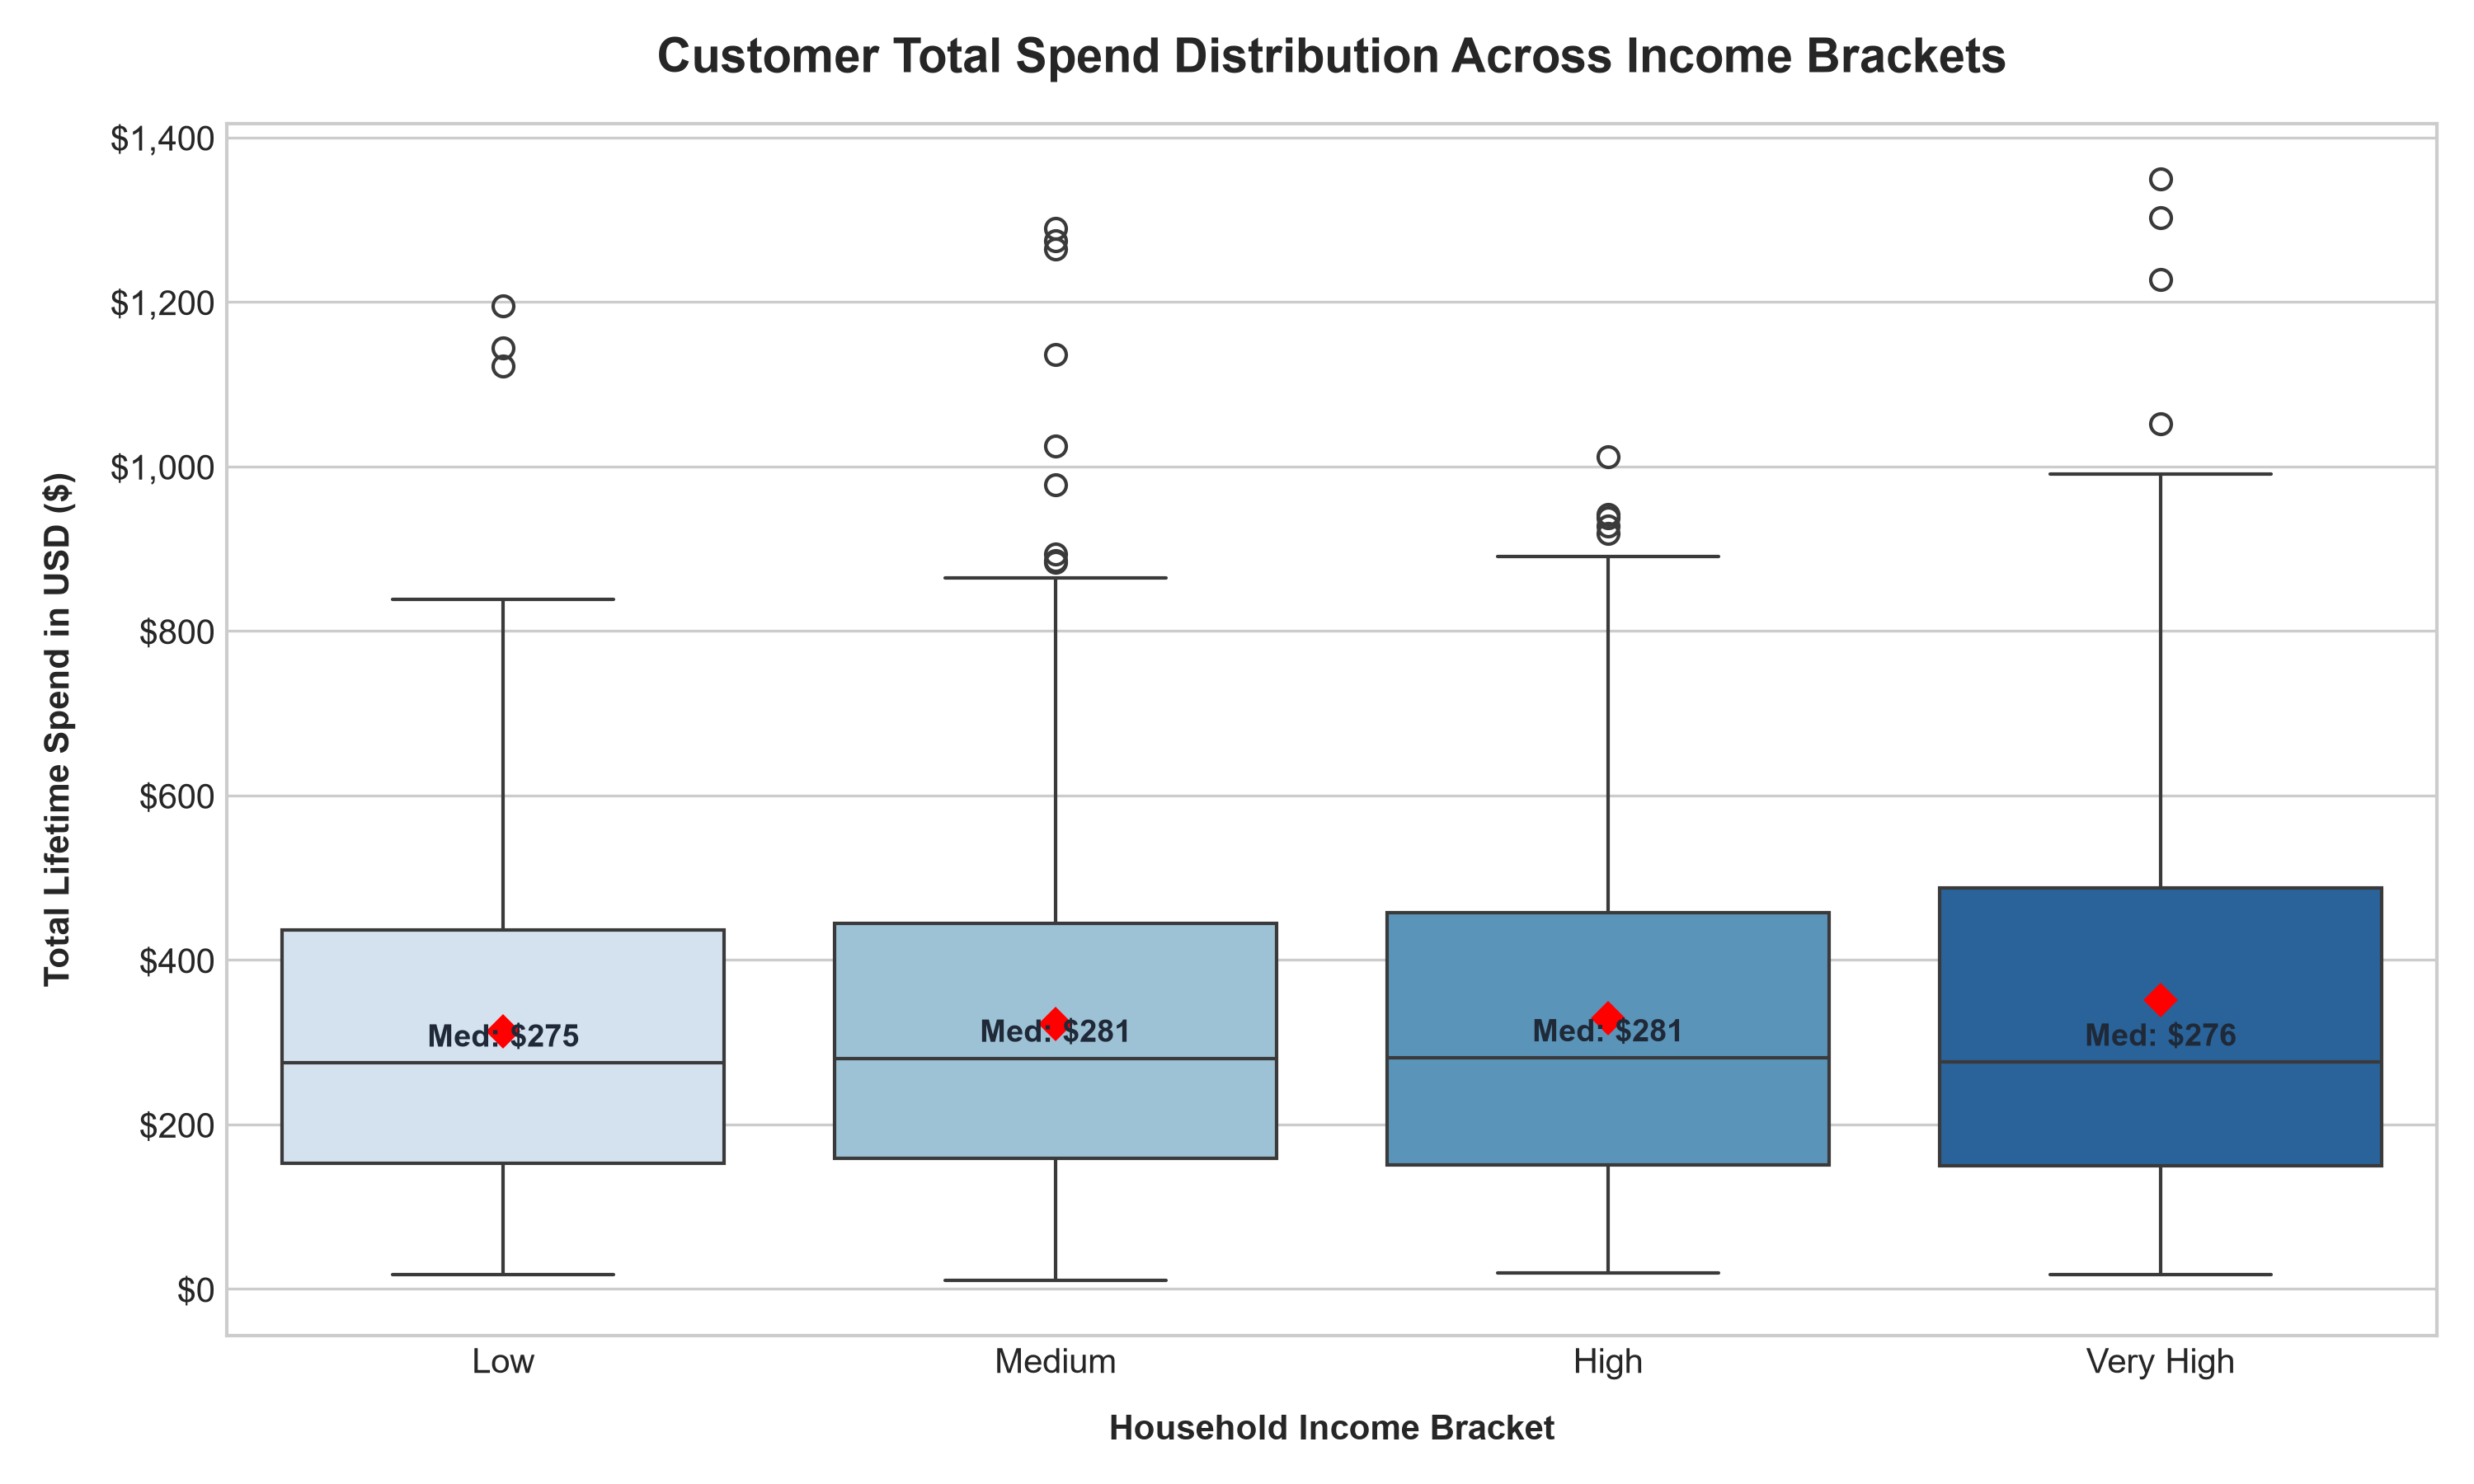

In [6]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='Income_Bracket', y='Total_Spend', data=df_clean[df_clean['Total_Orders'] > 0], palette='Blues')
plt.title('Spending Distribution Across Income Tiers')
plt.show()

## 8. Purchase Frequency Distribution

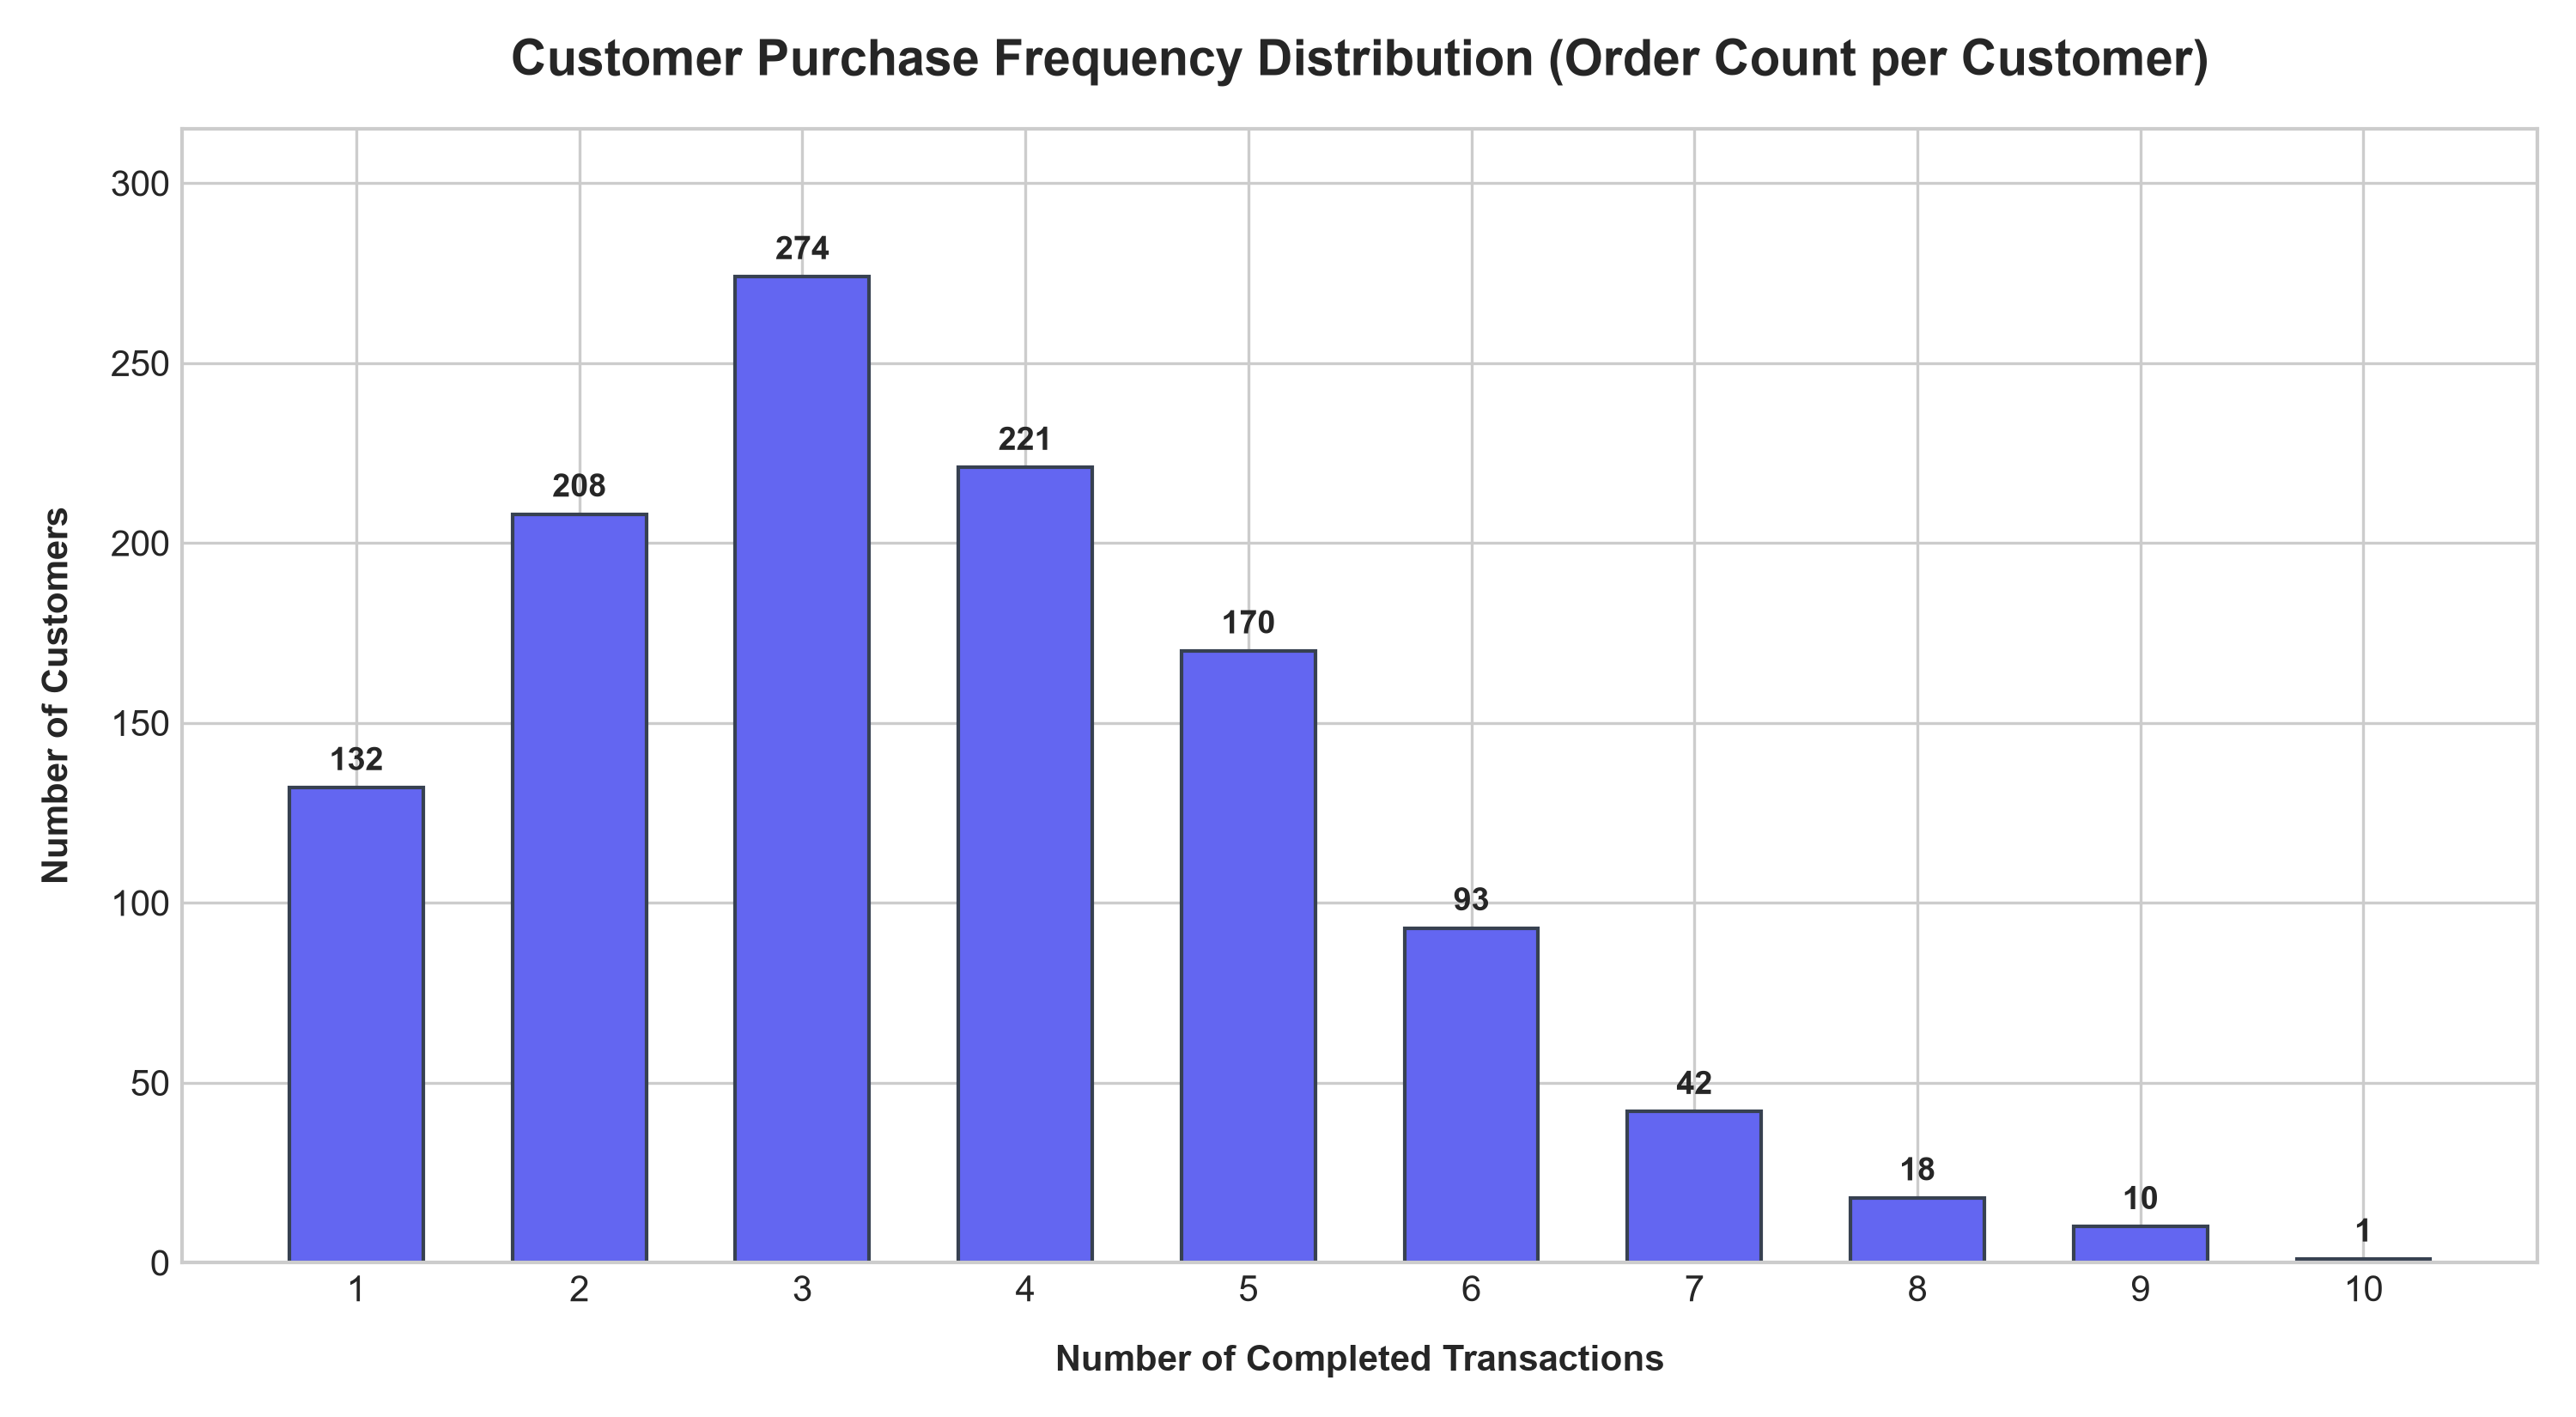

In [7]:
plt.figure(figsize=(10, 5))
df_clean[df_clean['Total_Orders'] > 0]['Total_Orders'].value_counts().sort_index().plot(kind='bar', color='#6366f1')
plt.title('Customer Order Frequency')
plt.show()

## 9. RFM Segment Revenue Share

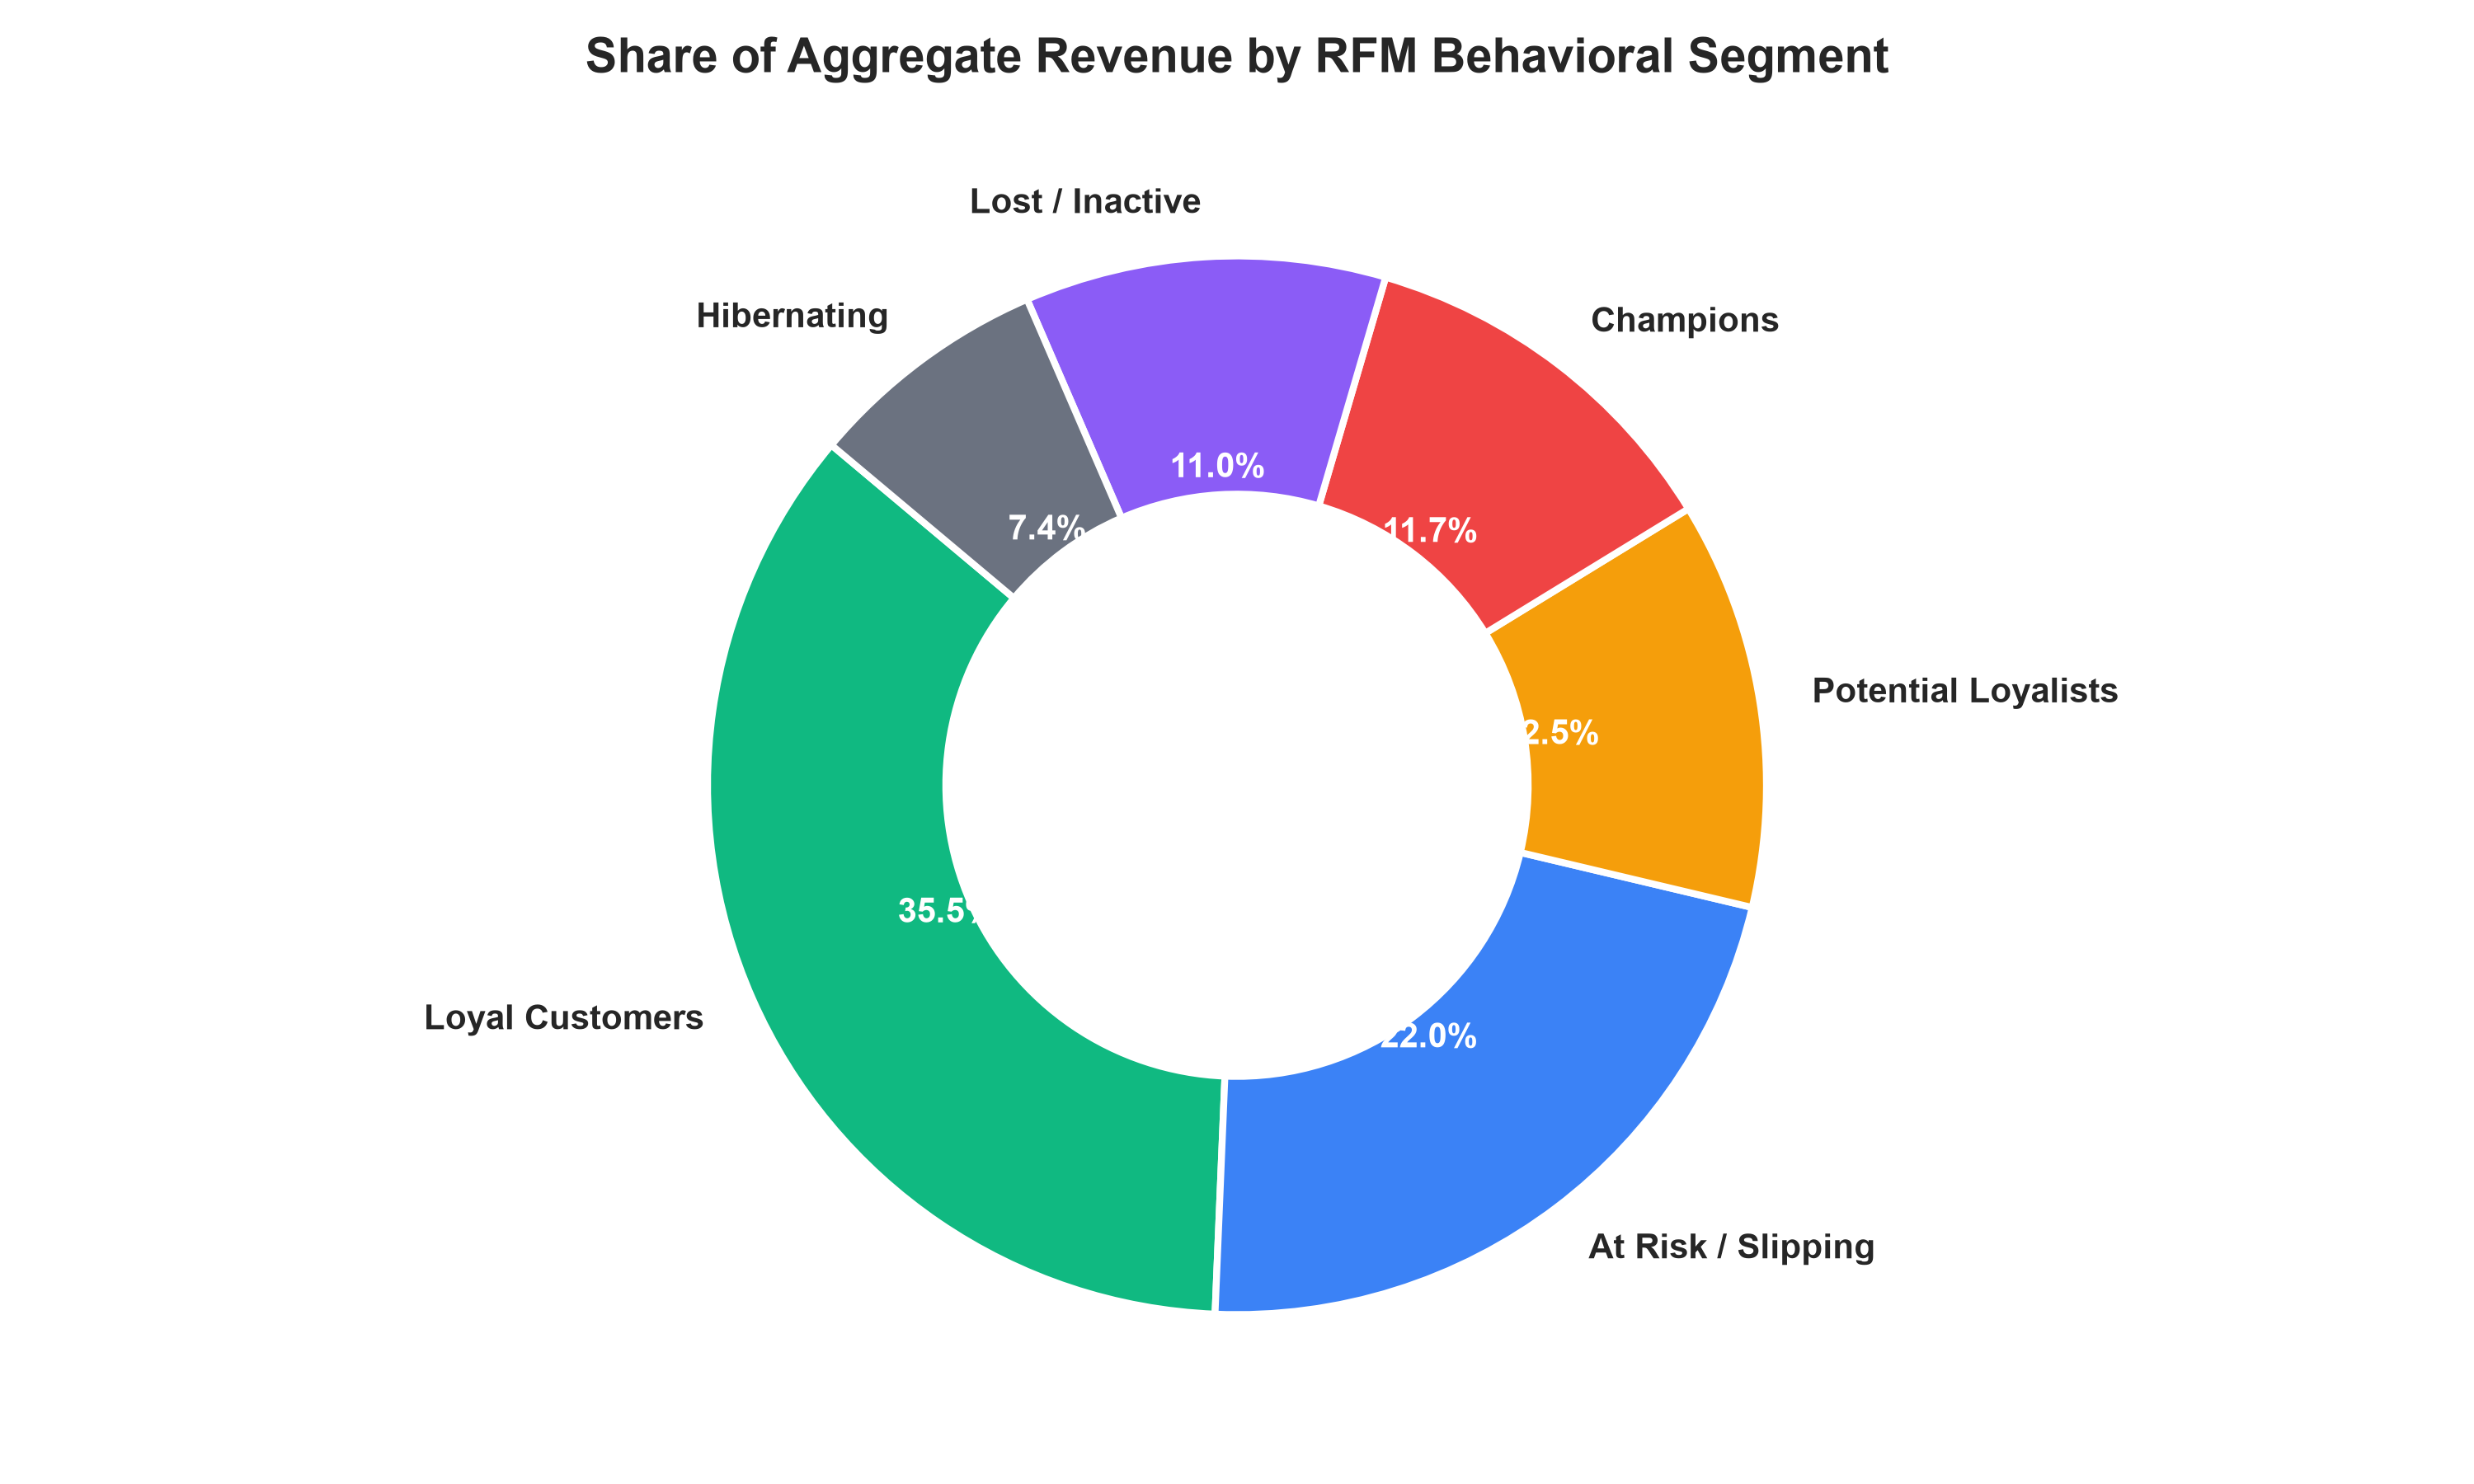

In [8]:
# Pie chart of RFM segment revenue
pass

## 10. Loyalty Tenure vs. Total Spend

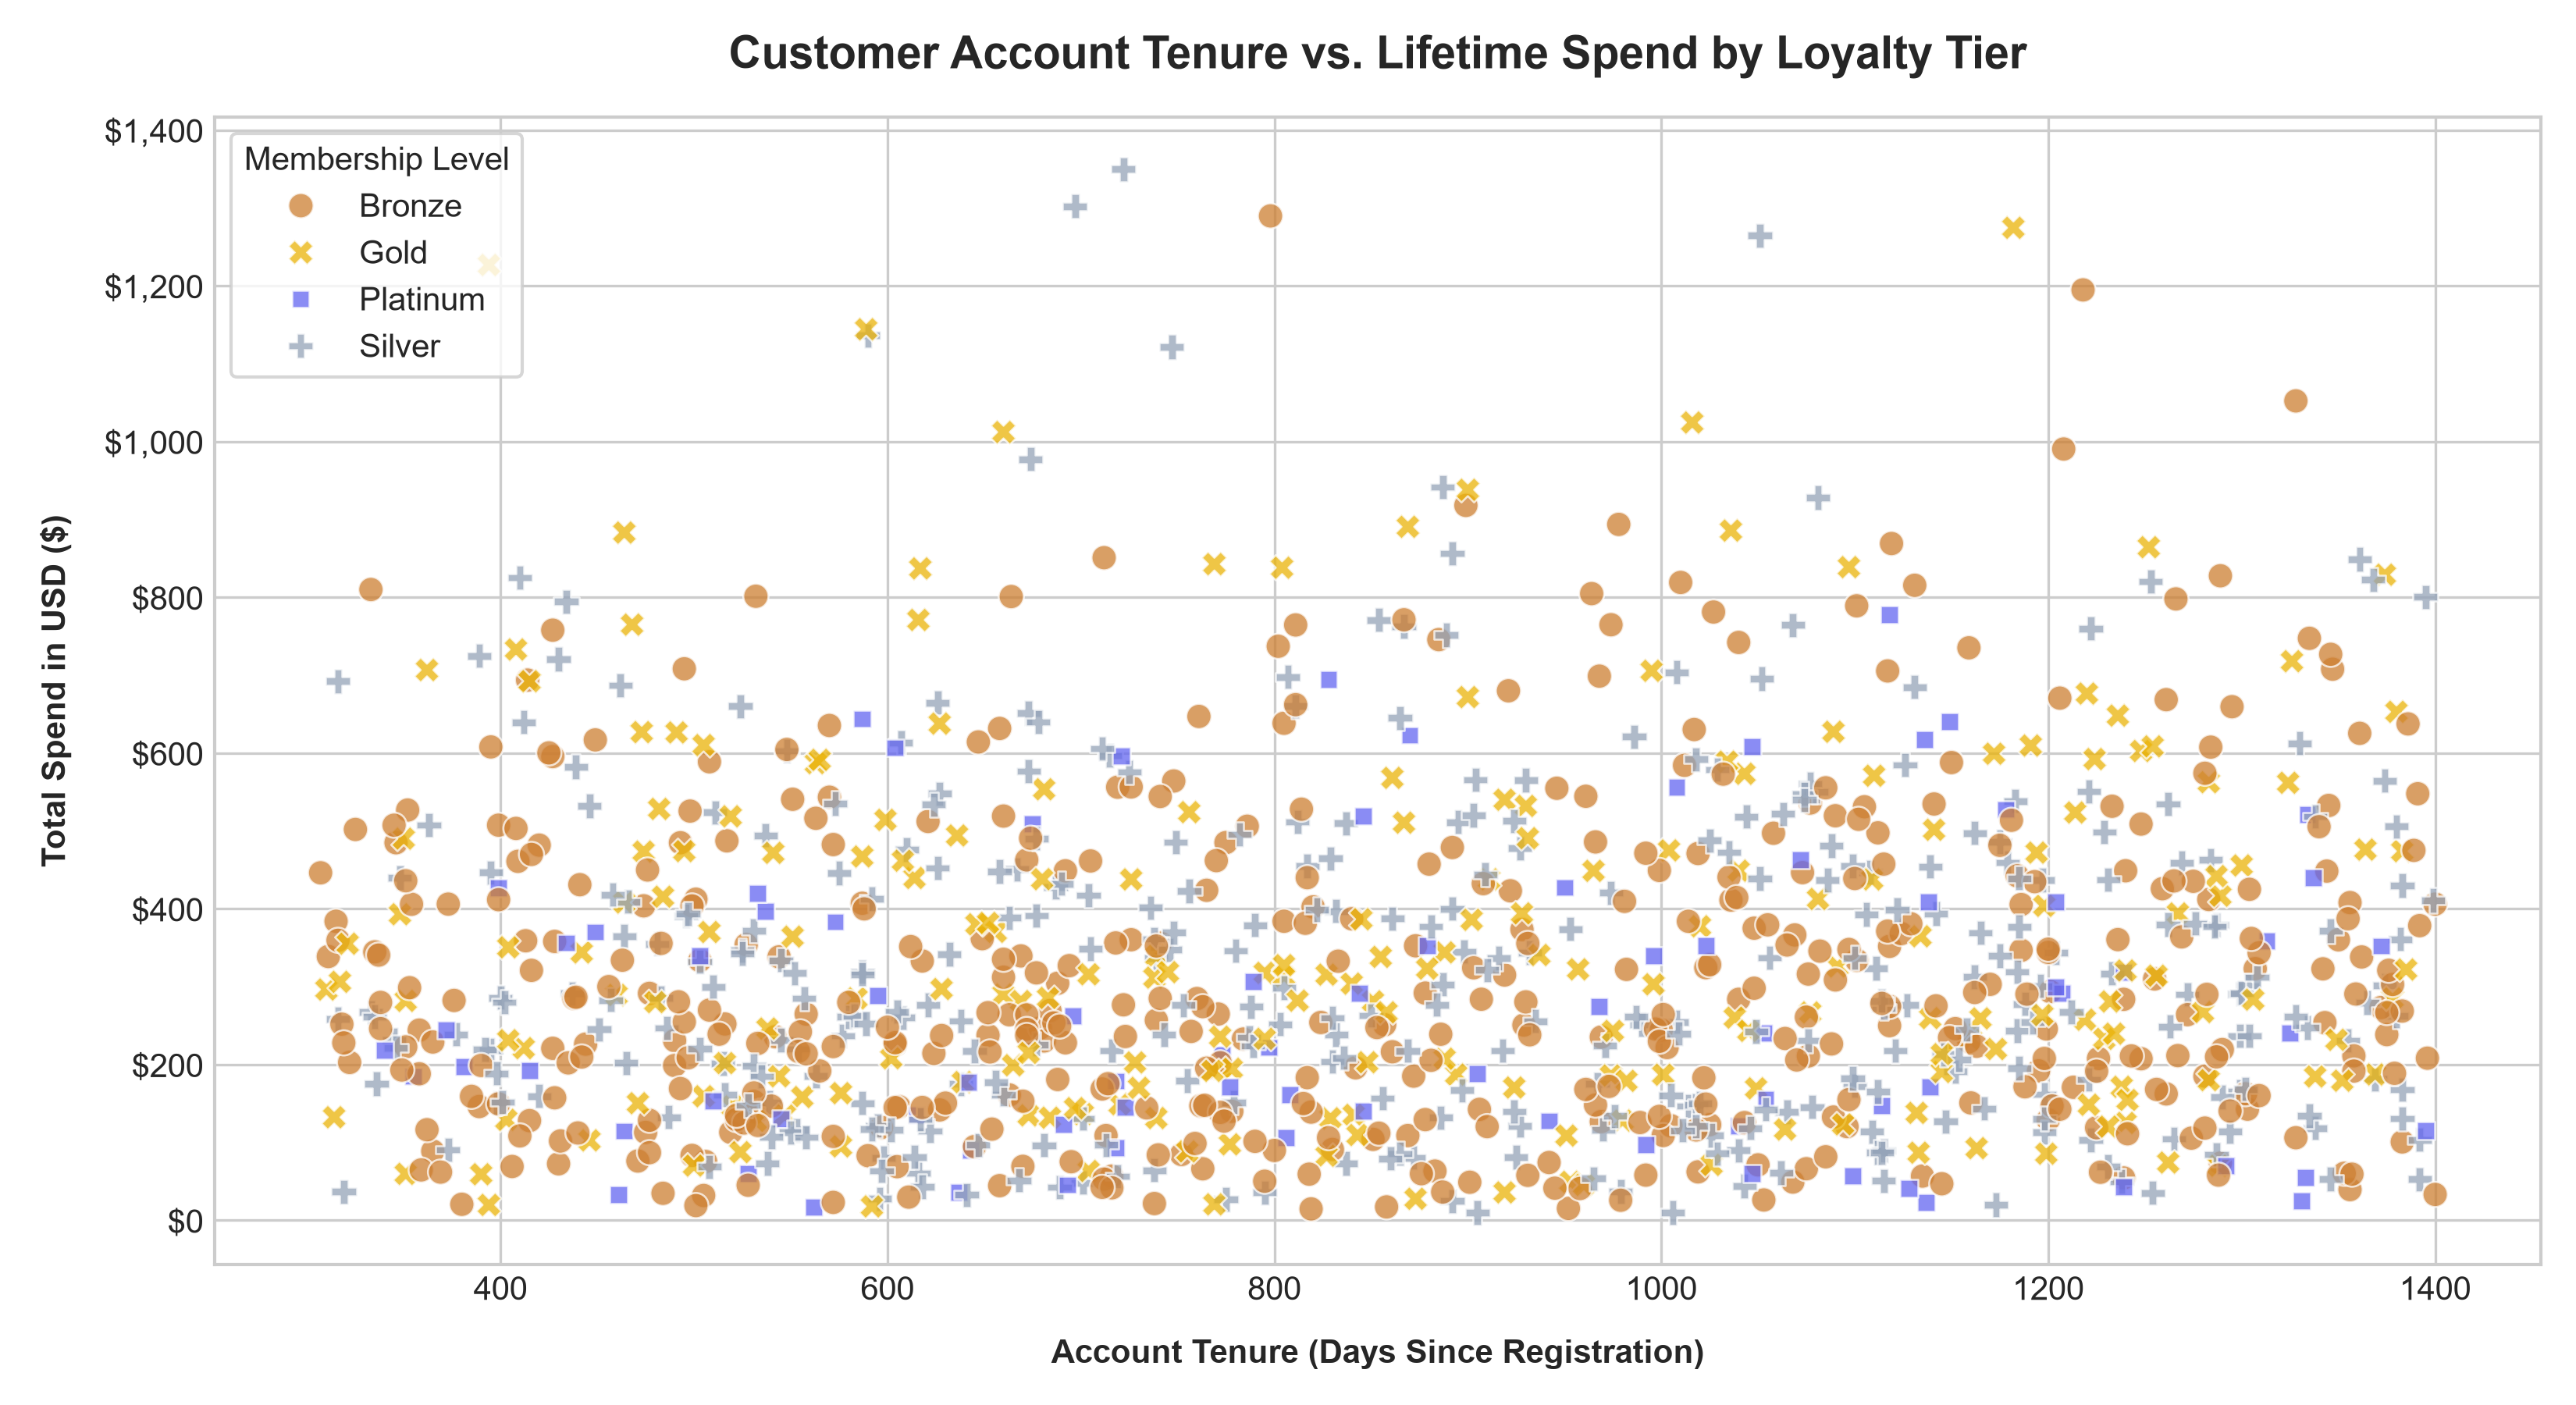

In [9]:
plt.figure(figsize=(11, 5))
sns.scatterplot(data=df_clean, x='Tenure_Days', y='Total_Spend', hue='Membership_Level')
plt.title('Tenure vs Lifetime Spend by Loyalty Tier')
plt.show()

## 11. Key Business Insights & Actionable Recommendations

### 💡 Key Findings:
1. **Loyal Customers & Champions Generate 47.2% of Total Revenue:**
   - Combined, these segments account for only **32.8%** of the active customer base but contribute **$179,289.57**.
   - Champions spend an average of **$655.19** with an average order frequency of **6.5 orders** and recent engagement within **39.5 days**.
2. **The 'At Risk / Slipping' Cohort Represents a $83.4k Vulnerability:**
   - **201 customers (17.2%)** who were historically frequent buyers (average 4.7 orders, $415.11 spend) have not made a purchase in an average of **358.5 days** (~1 year).
   - Without swift re-engagement, these accounts will transition into permanent churn.
3. **Mobile App is the Dominant Commercial Engine:**
   - Captures **56.62%** of all completed orders (2,378 transactions) and **$215,132.72** (56.60% of total revenue).
   - Web represents **34.31%** ($128.5k), while In-Store captures **9.07%** ($36.4k) with the highest average order size ($95.54).
4. **Income Bracket Dynamics:**
   - While 'Very High' income customers spend slightly more per transaction ($96.40 vs $89.18), the **Medium income bracket** drives the lion's share of company revenue (**$169,357.73** across 541 customers).

### 🎯 Actionable Recommendations:
1. **Deploy an Automated 'At Risk' Win-Back Trigger:** Trigger personalized promotional incentives (e.g. 15% discount on their preferred product category) for any customer whose recency crosses 120 days.
2. **VIP Loyalty & Early-Access Perks for Champions:** Launch an invite-only VIP program offering free expedited shipping and early-access drops to prevent Champions from exploring competitors.
3. **App-Exclusive Gamification:** Given that 56.6% of orders flow through the mobile app, implement in-app streak rewards and push notifications to accelerate the purchase cadence of 'Potential Loyalists'.
4. **In-Store Omnichannel Integration:** Use in-store QR code check-ins to capture digital profiles for physical retail buyers, boosting in-store frequency.